# Ejercicio Clase 1
1. Resolver el problema de la XOR con 3 neuronas:
    - Completar las 9 derivadas parciales.
    - Implementar SGD para entrenar el modelo.
    - Graficar MSE por epoch.
    - Una vez entrenado el modelo, realizar predicciones para verificar el funcionamiento.

## Diseño de la red

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, FancyBboxPatch

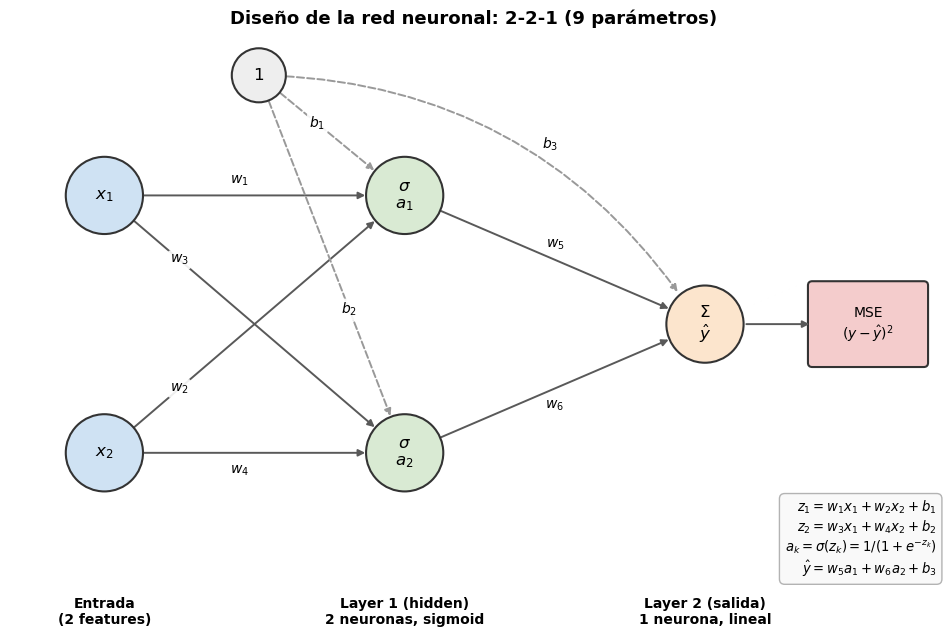

In [ ]:
def draw_network(params=None, title="Diseño de la red neuronal: 2-2-1 (9 parámetros)"):
    """Dibuja la red. Si se pasan `params`, muestra los valores entrenados en lugar de los nombres."""
    def label(name: str) -> str:
        return f"{name} = {params[name]:.2f}" if params is not None else f"${name[0]}_{name[1]}$"

    fig, ax = plt.subplots(figsize=(12, 7.8))
    ax.set_xlim(-0.6, 10.2)
    ax.set_ylim(-0.6, 6.4)
    ax.set_aspect("equal")
    ax.axis("off")

    r = 0.45
    nodes = {
        "x1": (0.5, 4.5), "x2": (0.5, 1.5),
        "h1": (4.0, 4.5), "h2": (4.0, 1.5),
        "out": (7.5, 3.0),
        "bias": (2.3, 5.9),
    }
    colors = {"x": "#cfe2f3", "h": "#d9ead3", "out": "#fce5cd", "bias": "#eeeeee"}

    def edge(a: str, b: str, text: str, t=0.5, offset=0.18, color="0.35", style="-"):
        (x0, y0), (x1, y1) = nodes[a], nodes[b]
        ax.annotate("", xy=(x1 - r * 0.95 * (x1 - x0) / ((x1 - x0) ** 2 + (y1 - y0) ** 2) ** 0.5,
                            y1 - r * 0.95 * (y1 - y0) / ((x1 - x0) ** 2 + (y1 - y0) ** 2) ** 0.5),
                    xytext=(x0, y0),
                    arrowprops=dict(arrowstyle="-|>", color=color, lw=1.4, linestyle=style, shrinkA=r * 28))
        xm, ym = x0 + t * (x1 - x0), y0 + t * (y1 - y0)
        ax.text(xm, ym + offset, text, ha="center", va="center", fontsize=10,
                bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.9))

    # Conexiones Layer 1
    edge("x1", "h1", label("w1"), t=0.45)
    edge("x2", "h1", label("w2"), t=0.25, offset=0.0)
    edge("x1", "h2", label("w3"), t=0.25, offset=0.0)
    edge("x2", "h2", label("w4"), t=0.45, offset=-0.2)
    # Conexiones Layer 2
    edge("h1", "out", label("w5"))
    edge("h2", "out", label("w6"), offset=-0.2)
    # Biases (entrada constante 1)
    edge("bias", "h1", label("b1"), t=0.4, offset=0.0, color="0.6", style="--")
    edge("bias", "h2", label("b2"), t=0.62, offset=0.0, color="0.6", style="--")
    ax.annotate("", xy=(nodes["out"][0] - 0.3, nodes["out"][1] + 0.35), xytext=nodes["bias"],
                arrowprops=dict(arrowstyle="-|>", color="0.6", lw=1.4, linestyle="--",
                                connectionstyle="arc3,rad=-0.25", shrinkA=r * 28))
    ax.text(5.7, 5.05, label("b3"), ha="center", fontsize=10,
            bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.9))

    # Neuronas
    texts = {
        "x1": ("$x_1$", colors["x"]), "x2": ("$x_2$", colors["x"]),
        "h1": ("$\\sigma$\n$a_1$", colors["h"]), "h2": ("$\\sigma$\n$a_2$", colors["h"]),
        "out": ("$\\Sigma$\n$\\hat{y}$", colors["out"]), "bias": ("1", colors["bias"]),
    }
    for name, (txt, fc) in texts.items():
        ax.add_patch(Circle(nodes[name], r * (0.7 if name == "bias" else 1), fc=fc, ec="0.2", lw=1.5, zorder=3))
        ax.text(*nodes[name], txt, ha="center", va="center", fontsize=12, zorder=4)

    # Loss
    ax.add_patch(FancyBboxPatch((8.75, 2.55), 1.3, 0.9, boxstyle="round,pad=0.05", fc="#f4cccc", ec="0.2", lw=1.5))
    ax.text(9.4, 3.0, "MSE\n$(y-\\hat{y})^2$", ha="center", va="center", fontsize=10)
    ax.annotate("", xy=(8.75, 3.0), xytext=(7.5 + r, 3.0), arrowprops=dict(arrowstyle="-|>", color="0.35", lw=1.4))

    # Títulos de capas
    for x, txt in [(0.5, "Entrada\n(2 features)"),
                   (4.0, "Layer 1 (hidden)\n2 neuronas, sigmoid"),
                   (7.5, "Layer 2 (salida)\n1 neurona, lineal")]:
        ax.text(x, -0.35, txt, ha="center", va="center", fontsize=10, fontweight="bold")

    # Ecuaciones del forward
    ax.text(10.2, 0.5,
            "$z_1 = w_1x_1 + w_2x_2 + b_1$\n"
            "$z_2 = w_3x_1 + w_4x_2 + b_2$\n"
            "$a_k = \\sigma(z_k) = 1/(1+e^{-z_k})$\n"
            "$\\hat{y} = w_5a_1 + w_6a_2 + b_3$",
            ha="right", va="center", fontsize=9.5,
            bbox=dict(boxstyle="round,pad=0.4", fc="#f9f9f9", ec="0.7"))

    ax.set_title(title, fontsize=13, fontweight="bold")
    plt.show()


draw_network()

| Layer | Neuronas | Activación | Pesos | Biases | Parámetros |
|---|---|---|---|---|---|
| Entrada | 2 ($x_1, x_2$) | — | — | — | 0 |
| Layer 1 (hidden) | 2 | sigmoid | 4 ($w_1 \ldots w_4$) | 2 ($b_1, b_2$) | 6 |
| Layer 2 (salida) | 1 | lineal (identidad) | 2 ($w_5, w_6$) | 1 ($b_3$) | 3 |
| **Total** | **3** | | **6** | **3** | **9** |

¿Por qué hace falta la capa hidden? La XOR no es linealmente separable: ninguna recta en el plano $(x_1, x_2)$ separa $\{(0,1),(1,0)\}$ de $\{(0,0),(1,1)\}$. Cada neurona hidden traza una recta (una frontera sigmoide), y la neurona de salida combina ambas para obtener la región que corresponde a la XOR.

## Arquitectura

Red de 3 neuronas (9 parámetros), igual a la vista en clase:

- **Layer 1 (hidden):** 2 neuronas con activación sigmoid
  - $z_1 = w_1 x_1 + w_2 x_2 + b_1, \quad a_1 = \sigma(z_1)$
  - $z_2 = w_3 x_1 + w_4 x_2 + b_2, \quad a_2 = \sigma(z_2)$
- **Layer 2 (salida):** 1 neurona sin activación
  - $\hat{y} = w_5 a_1 + w_6 a_2 + b_3$
- **Loss** (para Stocastic Gradient Descent): $L = (y - \hat{y})^2$

## Derivadas parciales

Usando regla de la cadena, con $\frac{\partial L}{\partial \hat{y}} = -2(y - \hat{y})$ y $\sigma'(z) = \sigma(z)(1 - \sigma(z))$:

**Layer 2:**

$$\frac{\partial L}{\partial w_5} = -2(y - \hat{y})\, a_1 \qquad
\frac{\partial L}{\partial w_6} = -2(y - \hat{y})\, a_2 \qquad
\frac{\partial L}{\partial b_3} = -2(y - \hat{y})$$

---

**Layer 1, neurona 1:**

$$\frac{\partial L}{\partial w_1} = -2(y - \hat{y})\, w_5\, a_1(1 - a_1)\, x_1 \qquad
\frac{\partial L}{\partial w_2} = -2(y - \hat{y})\, w_5\, a_1(1 - a_1)\, x_2 \qquad
\frac{\partial L}{\partial b_1} = -2(y - \hat{y})\, w_5\, a_1(1 - a_1)$$

**Layer 1, neurona 2:**

$$\frac{\partial L}{\partial w_3} = -2(y - \hat{y})\, w_6\, a_2(1 - a_2)\, x_1 \qquad
\frac{\partial L}{\partial w_4} = -2(y - \hat{y})\, w_6\, a_2(1 - a_2)\, x_2 \qquad
\frac{\partial L}{\partial b_2} = -2(y - \hat{y})\, w_6\, a_2(1 - a_2)$$

In [3]:
# Dataset XOR
X = np.array([[0, 0],
              [0, 1],
              [1, 0],
              [1, 1]], dtype=float)
y = np.array([0, 1, 1, 0], dtype=float)

In [ ]:
# 1 / ( 1+ e^{-z} )
def sigmoid(z):
    return 1 / (1 + np.exp(-z))


def forward(x1, x2, params):
    z1 = params["w1"] * x1 + params["w2"] * x2 + params["b1"]
    a1 = sigmoid(z1)
    z2 = params["w3"] * x1 + params["w4"] * x2 + params["b2"]
    a2 = sigmoid(z2)
    y_hat = params["w5"] * a1 + params["w6"] * a2 + params["b3"]
    return a1, a2, y_hat


def gradients(x1, x2, y_true, params):
    a1, a2, y_hat = forward(x1, x2, params)

    dL_dyhat = -2 * (y_true - y_hat)
    # Error propagado a la salida de cada neurona hidden (antes de multiplicar por la entrada)
    delta1 = dL_dyhat * params["w5"] * a1 * (1 - a1)
    delta2 = dL_dyhat * params["w6"] * a2 * (1 - a2)

    return {
        # Layer 1, neurona 1
        "w1": delta1 * x1,
        "w2": delta1 * x2,
        "b1": delta1,
        # Layer 1, neurona 2
        "w3": delta2 * x1,
        "w4": delta2 * x2,
        "b2": delta2,
        # Layer 2
        "w5": dL_dyhat * a1,
        "w6": dL_dyhat * a2,
        "b3": dL_dyhat,
    }


def mse(X, y, params):
    _, _, y_hat = forward(X[:, 0], X[:, 1], params)
    return np.mean((y - y_hat) ** 2)

## Entrenamiento con SGD

En cada epoch se recorren las 4 muestras en orden aleatorio y se actualizan los parámetros después de cada una: $\theta \leftarrow \theta - \eta \frac{\partial L}{\partial \theta}$.

In [5]:
def train_sgd(X, y, lr=0.1, epochs=5000, seed=0):
    rng = np.random.default_rng(seed)
    names = ["w1", "w2", "w3", "w4", "w5", "w6", "b1", "b2", "b3"]
    params = dict(zip(names, rng.normal(0, 1, len(names))))

    mse_history = []
    for epoch in range(epochs):
        for i in rng.permutation(len(X)):
            grads = gradients(X[i, 0], X[i, 1], y[i], params)
            for name in params:
                params[name] -= lr * grads[name]
        mse_history.append(mse(X, y, params))

    return params, mse_history


params, mse_history = train_sgd(X, y, lr=0.1, epochs=5000, seed=0)
print(f"MSE final: {mse_history[-1]:.2e}")

MSE final: 2.59e-31


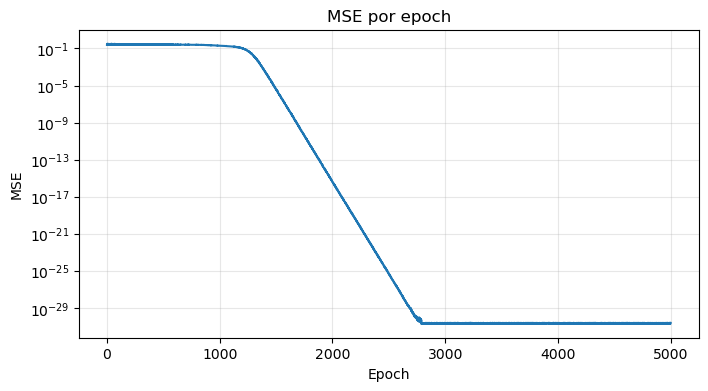

In [6]:
plt.figure(figsize=(8, 4))
plt.plot(mse_history)
plt.yscale("log")
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("MSE por epoch")
plt.grid(True, which="both", alpha=0.3)
plt.show()

## Predicciones

In [7]:
_, _, y_pred = forward(X[:, 0], X[:, 1], params)

print("x1  x2 | y  | y_hat    | clase")
for (x1, x2), y_true, y_hat in zip(X, y, y_pred):
    print(f"{x1:.0f}   {x2:.0f}  | {y_true:.0f}  | {y_hat:7.4f}  | {int(y_hat > 0.5)}")

print("\nParámetros entrenados:")
for name, value in params.items():
    print(f"  {name} = {value:.4f}")

x1  x2 | y  | y_hat    | clase
0   0  | 0  | -0.0000  | 0
0   1  | 1  |  1.0000  | 1
1   0  | 1  |  1.0000  | 1
1   1  | 0  |  0.0000  | 0

Parámetros entrenados:
  w1 = -3.6879
  w2 = -3.6948
  w3 = -1.5500
  w4 = -1.5511
  w5 = -3.3723
  w6 = 3.1882
  b1 = 0.4366
  b2 = 1.8520
  b3 = -0.7073


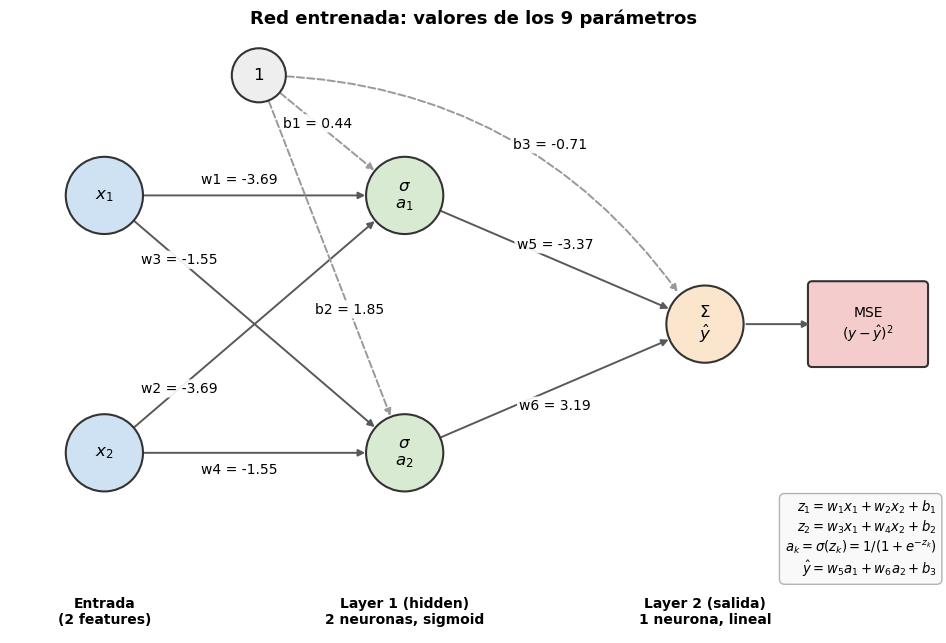

In [8]:
draw_network(params, title="Red entrenada: valores de los 9 parámetros")

**Nota:** con algunas inicializaciones el SGD puede quedar atrapado en un mínimo local (por ejemplo, `seed=9` termina con MSE ≈ 0.13 y no resuelve la XOR). Si pasa, basta con cambiar la semilla o el learning rate.